# PyTorch RNN-Based Question Answering System

### Professional end-to-end notebook | BiGRU classification + TF-IDF retrieval

This notebook turns the supplied question–answer CSV into a compact FAQ-style question answering system. It covers data inspection, text preprocessing, exploratory analysis, a bidirectional GRU classifier, nearest-question retrieval, confidence-aware abstention, evaluation diagnostics, and model export.

**Important dataset note:** the supplied file is named `100_Unique_QA_Dataset.csv`, but it currently contains **90 rows**, 90 distinct questions, and 85 distinct answer labels. The answers are all single-token labels. The neural model therefore performs **answer classification**, not unrestricted sentence generation.

**Output convention:** all chart images are saved in `images/`; checkpoints, metadata, metrics, histories, and retrieval assets are saved in `artifacts/`. Cells report completion and filenames only, not absolute filesystem locations.

> Recommended runtime: Python 3.10+ and PyTorch. GPU is optional; the notebook automatically selects CUDA, Apple MPS, or CPU.

## Notebook roadmap

1. Environment setup and dataset validation
2. Exploratory data analysis and visual reporting
3. Text normalization, tokenization, and vocabulary construction
4. PyTorch data pipeline and bidirectional GRU classifier
5. Diagnostic validation and model training
6. Final model training on the complete dataset
7. Hybrid inference: exact lookup, TF-IDF retrieval, GRU prediction, and abstention
8. Exported artifacts, plots, and final integrity checks

## 1. Environment and data validation

The notebook expects `100_Unique_QA_Dataset.csv` to be beside the notebook (or in a common notebook runtime upload directory). The path is used internally but is never printed in an output cell.

In [1]:
# 01 | Import core libraries
import os
import re
import json
import math
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader

from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, top_k_accuracy_score
from sklearn.decomposition import PCA
import joblib

print("Core libraries imported successfully.")

Core libraries imported successfully.


In [2]:
# 02 | Keep notebook output clean and reproducible
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 140)

print(f"Python environment ready | PyTorch {torch.__version__}")

Python environment ready | PyTorch 2.14.1+cu132


In [3]:
# 03 | Reproducibility configuration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Keep CPU execution efficient on small datasets.
torch.set_num_threads(min(4, os.cpu_count() or 1))

print(f"Random seed set to {SEED}.")

Random seed set to 42.


In [4]:
# 04 | Project folders
PROJECT_ROOT = Path.cwd()
IMAGE_DIR = PROJECT_ROOT / "images"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folders are ready: images/ and artifacts/.")

Project folders are ready: images/ and artifacts/.


In [5]:
# 05 | Locate the supplied dataset without displaying its location
DATASET_NAME = "100_Unique_QA_Dataset.csv"
candidates = [
    PROJECT_ROOT / DATASET_NAME,
    Path("/content") / DATASET_NAME,
    Path("/mnt/data") / DATASET_NAME,
]
DATASET_FILE = next((candidate for candidate in candidates if candidate.is_file()), None)

if DATASET_FILE is None:
    raise FileNotFoundError("Upload 100_Unique_QA_Dataset.csv beside the notebook, then rerun this cell.")

print("Dataset found and ready to load.")

Dataset found and ready to load.


In [6]:
# 06 | Load the question-answer dataset
raw_df = pd.read_csv(DATASET_FILE)
df = raw_df.copy()

print(f"Loaded {len(df):,} question-answer pairs.")

Loaded 90 question-answer pairs.


In [7]:
# 07 | Preview the dataset
display(df.head(10))

,question,answer
0,What is the capital of France?,Paris
1,What is the capital of Germany?,Berlin
2,Who wrote 'To Kill a Mockingbird'?,Harper-Lee
3,What is the largest planet in our solar system?,Jupiter
4,What is the boiling point of water in Celsius?,100
5,Who painted the Mona Lisa?,Leonardo-da-Vinci
6,What is the square root of 64?,8
7,What is the chemical symbol for gold?,Au
8,Which year did World War II end?,1945
9,What is the longest river in the world?,Nile


In [8]:
# 08 | Inspect the schema and data types
schema_summary = pd.DataFrame({
    "column": df.columns,
    "data_type": [str(dtype) for dtype in df.dtypes],
    "missing_values": [int(df[column].isna().sum()) for column in df.columns],
    "unique_values": [int(df[column].nunique(dropna=True)) for column in df.columns],
})
display(schema_summary)

,column,data_type,missing_values,unique_values
0,question,str,0,90
1,answer,str,0,85


In [9]:
# 09 | Validate the expected input columns
required_columns = {"question", "answer"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"The dataset is missing required columns: {sorted(missing_columns)}")

print("Required question and answer columns are present.")

Required question and answer columns are present.


In [10]:
# 10 | Remove incomplete and duplicate records
df = df.dropna(subset=["question", "answer"]).copy()
df["question"] = df["question"].astype(str).str.strip()
df["answer"] = df["answer"].astype(str).str.strip()
df = df[(df["question"] != "") & (df["answer"] != "")]
df = df.drop_duplicates(subset=["question"], keep="first").reset_index(drop=True)

print(f"Dataset cleaned: {len(df):,} unique questions remain.")

Dataset cleaned: 90 unique questions remain.


In [11]:
# 11 | Create normalized text fields for matching

def normalize_text(text):
    """Normalize case, punctuation, and whitespace for robust matching."""
    text = str(text).casefold().strip()
    text = re.sub(r"[^a-z0-9\s'-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["question_normalized"] = df["question"].map(normalize_text)
print("Normalized question text created.")

Normalized question text created.


In [12]:
# 12 | Confirm dataset uniqueness after cleaning
quality_report = {
    "rows": int(len(df)),
    "unique_questions": int(df["question_normalized"].nunique()),
    "unique_answers": int(df["answer"].nunique()),
    "duplicate_questions": int(df["question_normalized"].duplicated().sum()),
    "missing_questions": int(df["question"].isna().sum()),
    "missing_answers": int(df["answer"].isna().sum()),
}
display(pd.Series(quality_report, name="value").to_frame())

,value
rows,90
unique_questions,90
unique_answers,85
duplicate_questions,0
missing_questions,0
missing_answers,0


In [13]:
# 13 | Answer frequency table
answer_counts = df["answer"].value_counts().rename_axis("answer").reset_index(name="count")
display(answer_counts.head(15))

,answer,count
0,8,3
1,7,2
2,Hydrogen,2
3,Mercury,2
4,Paris,1
5,Berlin,1
6,Harper-Lee,1
7,Jupiter,1
8,100,1
9,Leonardo-da-Vinci,1


In [14]:
# 14 | Question and answer length features
df["question_word_count"] = df["question"].str.split().str.len()
df["answer_word_count"] = df["answer"].str.split().str.len()
df["question_char_count"] = df["question"].str.len()
df["answer_char_count"] = df["answer"].str.len()

display(df[["question_word_count", "answer_word_count", "question_char_count", "answer_char_count"]].describe().round(2))

,question_word_count,answer_word_count,question_char_count,answer_char_count
count,90.00,90.0,90.00,90.00
mean,6.98,1.0,37.22,7.17
std,1.59,0.0,7.51,4.41
min,3.00,1.0,23.00,1.00
25%,6.00,1.0,30.25,5.00
50%,7.00,1.0,37.00,6.00
75%,8.00,1.0,43.00,9.00
max,12.00,1.0,63.00,21.00


In [15]:
# 15 | Validate the answer format used by this model
answer_length_distribution = df["answer_word_count"].value_counts().sort_index()
display(answer_length_distribution.rename("records").to_frame())

if answer_length_distribution.index.max() != 1:
    raise ValueError("This notebook is configured for single-token answer classification; review the answer format first.")

print("All answers are single-token labels, matching the classifier design.")

,records
answer_word_count,
1,90


All answers are single-token labels, matching the classifier design.


In [16]:
# 16 | Build a quick text-frequency overview
all_question_words = " ".join(df["question"].tolist()).lower().split()
question_word_counts = Counter(all_question_words)
print(f"Total question tokens: {len(all_question_words):,}")
print(f"Unique whitespace-delimited tokens: {len(question_word_counts):,}")

Total question tokens: 628
Unique whitespace-delimited tokens: 251


In [17]:
# 17 | Inspect the most frequent words
most_common_words = pd.DataFrame(question_word_counts.most_common(20), columns=["word", "frequency"])
display(most_common_words)

,word,frequency
0,the,73
1,is,56
2,what,38
3,of,31
4,which,28
5,who,18
6,in,16
7,capital,12
8,a,9
9,for,8


In [18]:
# 18 | Check the number of repeated answer labels
repeated_answers = df["answer"].value_counts()
repeated_answers = repeated_answers[repeated_answers > 1]
display(repeated_answers.rename("frequency").to_frame())

,frequency
answer,
8,3
7,2
Hydrogen,2
Mercury,2


In [19]:
# 19 | Add a compact dataset profile
profile = {
    "records": len(df),
    "unique answers": df["answer"].nunique(),
    "mean question words": round(df["question_word_count"].mean(), 2),
    "maximum question words": int(df["question_word_count"].max()),
    "mean question characters": round(df["question_char_count"].mean(), 2),
    "single-token answer share": round((df["answer_word_count"] == 1).mean() * 100, 1),
}
display(pd.DataFrame(profile.items(), columns=["metric", "value"]))

,metric,value
0,records,90.00
1,unique answers,85.00
2,mean question words,6.98
3,maximum question words,12.00
4,mean question characters,37.22
5,single-token answer share,100.00


In [20]:
# 20 | Configure a consistent visual theme
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
PALETTE = sns.color_palette("mako", 8)
ACCENT_PALETTE = sns.color_palette("husl", 10)
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "savefig.facecolor": "white",
})
print("Visualization theme configured.")

Visualization theme configured.


In [21]:
# 21 | Centralized figure-saving helper
def save_figure(fig, filename, dpi=180):
    """Save a chart in images/ without displaying filesystem locations."""
    fig.savefig(IMAGE_DIR / filename, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"Saved image: {filename}")

print("Chart export helper is ready.")

Chart export helper is ready.


Saved image: 01_dataset_overview.png


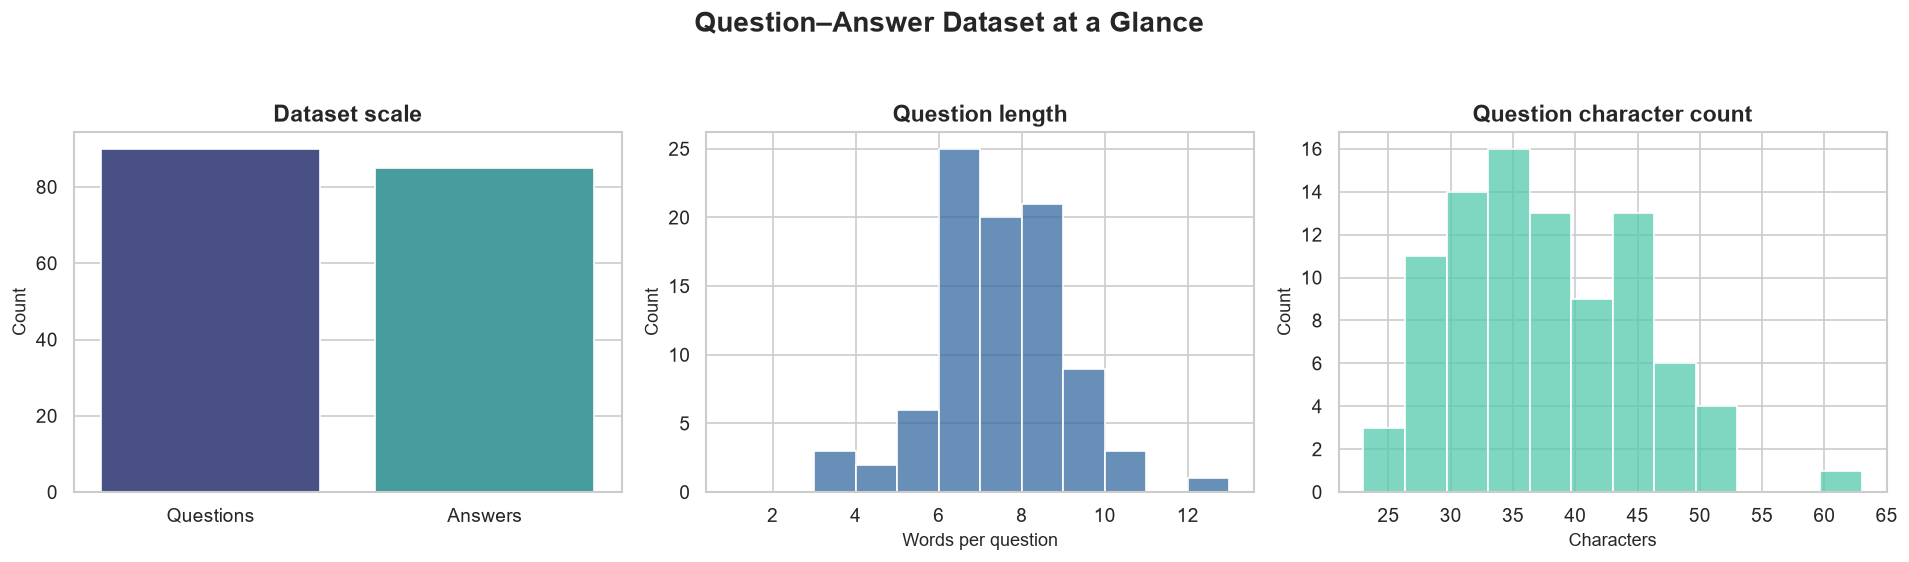

In [22]:
# 22 | Dataset overview dashboard
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(x=["Questions", "Answers"], y=[len(df), df["answer"].nunique()], hue=["Questions", "Answers"], palette=[PALETTE[2], PALETTE[5]], legend=False, ax=axes[0])
axes[0].set_title("Dataset scale")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("")
sns.histplot(df["question_word_count"], bins=range(1, int(df["question_word_count"].max()) + 2), color=PALETTE[3], ax=axes[1])
axes[1].set_title("Question length")
axes[1].set_xlabel("Words per question")
sns.histplot(df["question_char_count"], bins=12, color=PALETTE[6], ax=axes[2])
axes[2].set_title("Question character count")
axes[2].set_xlabel("Characters")
fig.suptitle("Question–Answer Dataset at a Glance", fontsize=17, fontweight="bold", y=1.04)
fig.tight_layout()
save_figure(fig, "01_dataset_overview.png")
plt.show()

Saved image: 02_answer_frequency.png


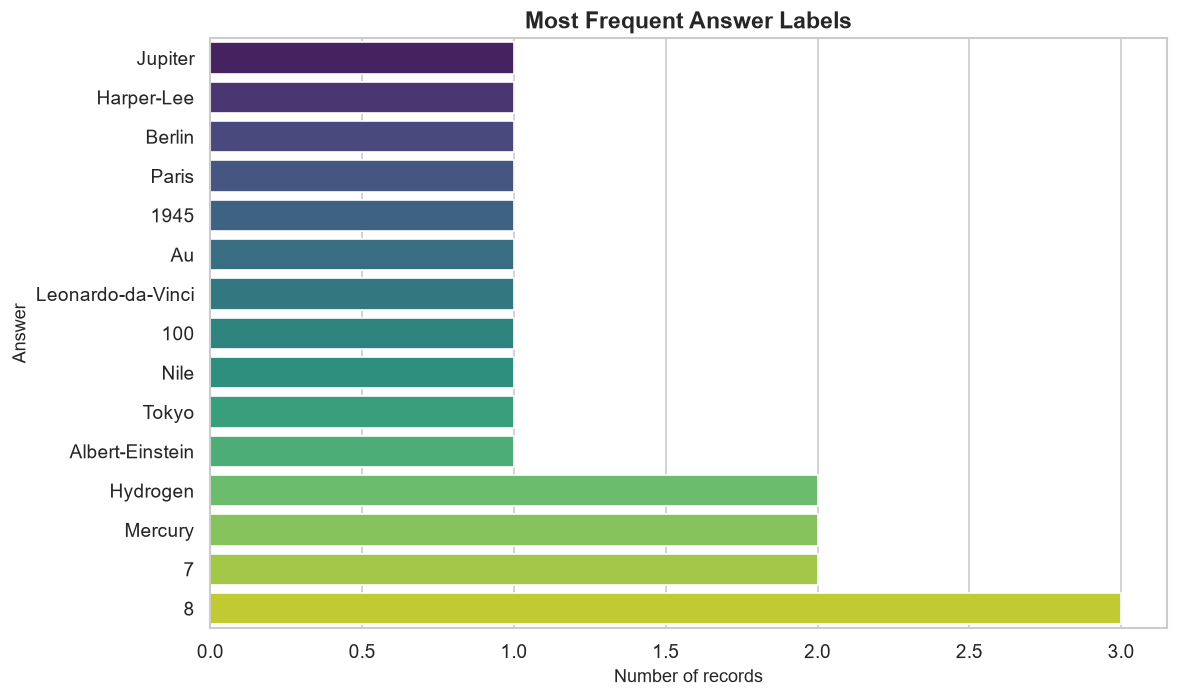

In [23]:
# 23 | Plot the most common answer labels
plot_answers = df["answer"].value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=plot_answers.values, y=plot_answers.index, hue=plot_answers.index, palette="viridis", legend=False, ax=ax)
ax.set_title("Most Frequent Answer Labels")
ax.set_xlabel("Number of records")
ax.set_ylabel("Answer")
fig.tight_layout()
save_figure(fig, "02_answer_frequency.png")
plt.show()

Saved image: 03_question_length_distribution.png


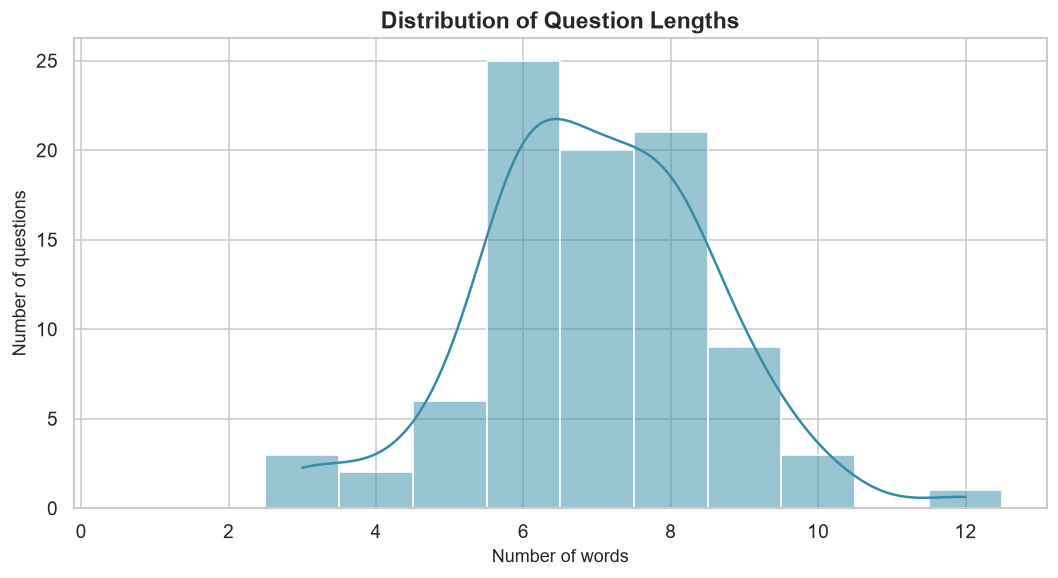

In [24]:
# 24 | Visualize question word-count distribution
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="question_word_count", bins=np.arange(1, df["question_word_count"].max() + 2) - 0.5, kde=True, color=PALETTE[4], ax=ax)
ax.set_title("Distribution of Question Lengths")
ax.set_xlabel("Number of words")
ax.set_ylabel("Number of questions")
fig.tight_layout()
save_figure(fig, "03_question_length_distribution.png")
plt.show()

Saved image: 04_text_length_comparison.png


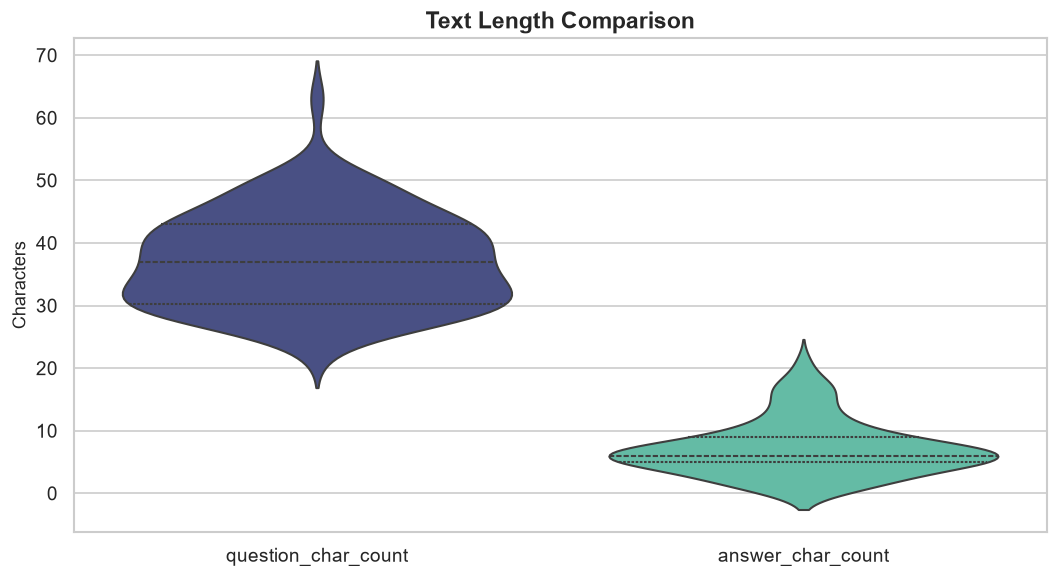

In [25]:
# 25 | Compare question and answer character lengths
length_frame = df[["question_char_count", "answer_char_count"]].melt(var_name="text_type", value_name="characters")
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=length_frame, x="text_type", y="characters", hue="text_type", palette=[PALETTE[2], PALETTE[6]], legend=False, inner="quartile", ax=ax)
ax.set_title("Text Length Comparison")
ax.set_xlabel("")
ax.set_ylabel("Characters")
fig.tight_layout()
save_figure(fig, "04_text_length_comparison.png")
plt.show()

Saved image: 05_frequent_question_terms.png


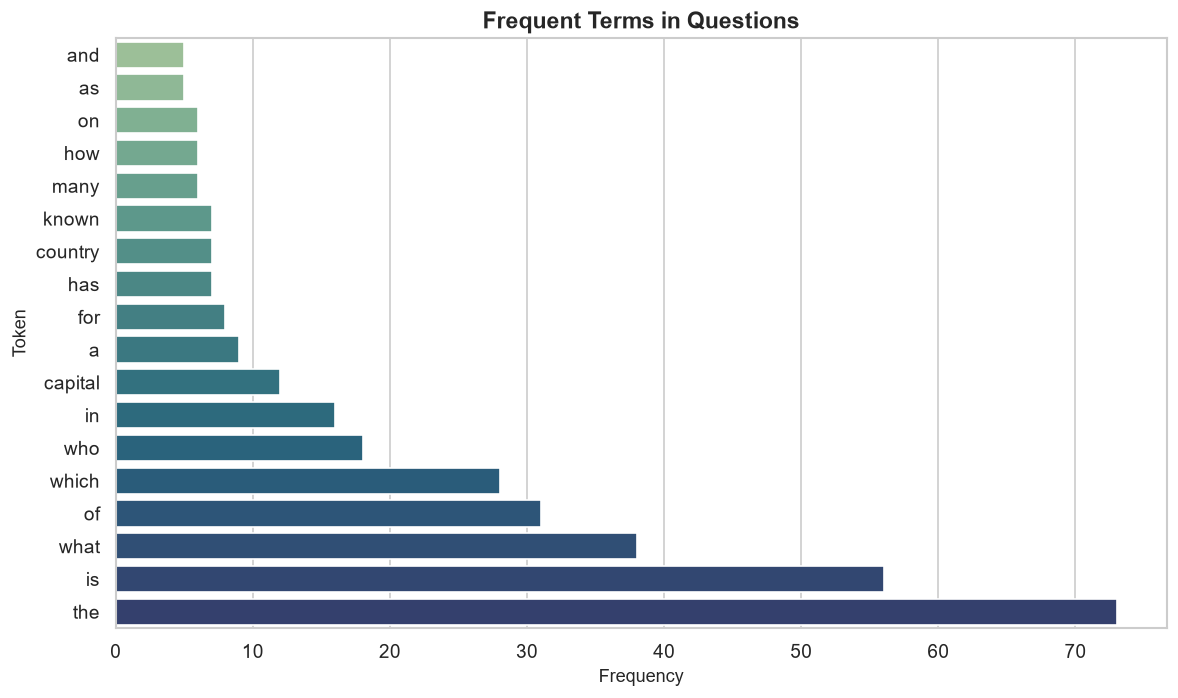

In [26]:
# 26 | Plot frequent question terms
plot_words = most_common_words.head(18).sort_values("frequency")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_words, x="frequency", y="word", hue="word", palette="crest", legend=False, ax=ax)
ax.set_title("Frequent Terms in Questions")
ax.set_xlabel("Frequency")
ax.set_ylabel("Token")
fig.tight_layout()
save_figure(fig, "05_frequent_question_terms.png")
plt.show()

Saved image: 06_answer_label_frequency_distribution.png


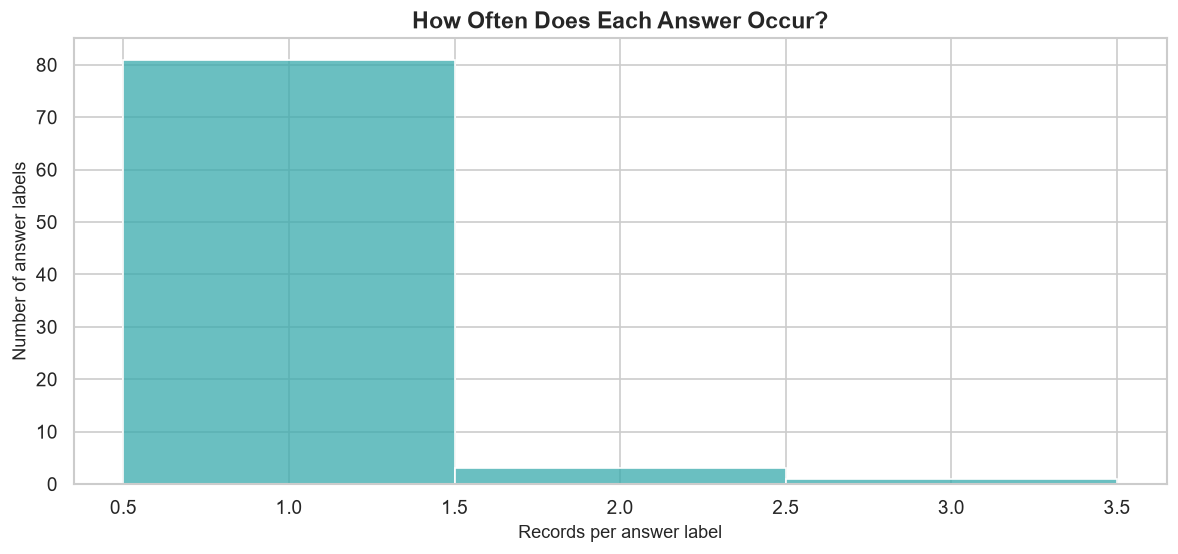

In [27]:
# 27 | Inspect answer-label imbalance
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(df["answer"].value_counts(), discrete=True, color=PALETTE[5], ax=ax)
ax.set_title("How Often Does Each Answer Occur?")
ax.set_xlabel("Records per answer label")
ax.set_ylabel("Number of answer labels")
fig.tight_layout()
save_figure(fig, "06_answer_label_frequency_distribution.png")
plt.show()

### Dataset contract

Required fields are `question` and `answer`. Empty rows and duplicate questions are removed. Original answer strings are retained as class labels so returned answers preserve the dataset's spelling and formatting.

In [28]:
# 28 | Create a tokenization function
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:[-'][a-z0-9]+)*")

def tokenize(text):
    """Lowercase tokenization that preserves compound hyphenated names."""
    return TOKEN_PATTERN.findall(str(text).casefold())

print("Tokenization examples:")
for sample in df["question"].head(3):
    print(f"• {sample}  →  {tokenize(sample)}")

Tokenization examples:
• What is the capital of France?  →  ['what', 'is', 'the', 'capital', 'of', 'france']
• What is the capital of Germany?  →  ['what', 'is', 'the', 'capital', 'of', 'germany']
• Who wrote 'To Kill a Mockingbird'?  →  ['who', 'wrote', 'to', 'kill', 'a', 'mockingbird']


In [29]:
# 29 | Create tokenized question and answer columns
df["question_tokens"] = df["question"].map(tokenize)
df["answer_tokens"] = df["answer"].map(tokenize)
display(df[["question", "question_tokens", "answer", "answer_tokens"]].head(5))

,question,question_tokens,answer,answer_tokens
0,What is the capital of France?,"[what, is, the, capital, of, france]",Paris,[paris]
1,What is the capital of Germany?,"[what, is, the, capital, of, germany]",Berlin,[berlin]
2,Who wrote 'To Kill a Mockingbird'?,"[who, wrote, to, kill, a, mockingbird]",Harper-Lee,[harper-lee]
3,What is the largest planet in our solar system?,"[what, is, the, largest, planet, in, our, solar, system]",Jupiter,[jupiter]
4,What is the boiling point of water in Celsius?,"[what, is, the, boiling, point, of, water, in, celsius]",100,[100]


In [30]:
# 30 | Recalculate token lengths with the model tokenizer
df["token_count"] = df["question_tokens"].str.len()
token_length_summary = df["token_count"].describe().round(2)
display(token_length_summary.to_frame(name="question_tokens"))

,question_tokens
count,90.00
mean,6.98
std,1.59
min,3.00
25%,6.00
50%,7.00
75%,8.00
max,12.00


In [31]:
# 31 | Identify the longest questions for inspection
longest_questions = df.nlargest(8, "token_count")[["question", "answer", "token_count"]]
display(longest_questions)

,question,answer,token_count
84,Which Disney character has a long nose and grows it when lying?,Pinocchio,12
37,Who was the first person to step on the Moon?,Armstrong,10
46,Which bird is known for its ability to mimic sounds?,Parrot,10
74,Who was the first female Prime Minister of the UK?,MargaretThatcher,10
3,What is the largest planet in our solar system?,Jupiter,9
4,What is the boiling point of water in Celsius?,100,9
12,What is the freezing point of water in Fahrenheit?,32,9
45,Who was the first President of the United States?,George-Washington,9


In [32]:
# 32 | Create an answer vocabulary
answer_labels = sorted(df["answer"].unique().tolist())
answer_to_idx = {answer: index for index, answer in enumerate(answer_labels)}
idx_to_answer = {index: answer for answer, index in answer_to_idx.items()}
NUM_CLASSES = len(answer_labels)

print(f"Answer classes: {NUM_CLASSES}")

Answer classes: 85


In [33]:
# 33 | Check label encoding consistency
label_check = pd.DataFrame({
    "answer": answer_labels[:12],
    "class_id": [answer_to_idx[answer] for answer in answer_labels[:12]],
})
display(label_check)

,answer,class_id
0,100,0
1,12,1
2,1945,2
3,2,3
4,206,4
5,"299,792,458m/s",5
6,32,6
7,6,7
8,7,8
9,8,9


In [34]:
# 34 | Build a leakage-aware diagnostic split
# Hold out one example only for labels that have multiple examples.
# This produces a small, deliberately limited validation set while keeping every
# validation answer represented in the training set.
val_indices = []
for answer, count in df["answer"].value_counts().items():
    if count >= 2:
        matching_indices = df.index[df["answer"] == answer].tolist()
        val_indices.append(matching_indices[-1])

train_indices = [index for index in df.index if index not in set(val_indices)]
train_df = df.loc[train_indices].reset_index(drop=True)
val_df = df.loc[val_indices].reset_index(drop=True)

print(f"Training records: {len(train_df)} | Validation records: {len(val_df)}")

Training records: 86 | Validation records: 4


In [35]:
# 35 | Verify validation labels are represented in training
train_answer_set = set(train_df["answer"])
validation_unseen_labels = set(val_df["answer"]).difference(train_answer_set)
assert not validation_unseen_labels, "Validation includes answer labels absent from training."

print("Every validation answer class is represented in the training split.")

Every validation answer class is represented in the training split.


In [36]:
# 36 | Build a question-token vocabulary from training questions only
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

def build_vocab(texts, min_frequency=1):
    frequencies = Counter(token for text in texts for token in tokenize(text))
    vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for token, frequency in sorted(frequencies.items()):
        if frequency >= min_frequency and token not in vocab:
            vocab[token] = len(vocab)
    return vocab

vocab = build_vocab(train_df["question"].tolist())
print(f"Diagnostic vocabulary size: {len(vocab)}")

Diagnostic vocabulary size: 238


In [37]:
# 37 | Inspect vocabulary coverage
train_token_set = {token for question in train_df["question"] for token in tokenize(question)}
val_token_set = {token for question in val_df["question"] for token in tokenize(question)}
known_val_tokens = val_token_set.intersection(set(vocab))
coverage = len(known_val_tokens) / max(1, len(val_token_set))
print(f"Validation token coverage: {coverage:.1%}")

Validation token coverage: 66.7%


In [38]:
# 38 | Convert questions into integer sequences
def text_to_indices(text, vocabulary):
    tokens = tokenize(text)
    return [vocabulary.get(token, vocabulary[UNK_TOKEN]) for token in tokens] or [vocabulary[UNK_TOKEN]]

sample_question = train_df.loc[0, "question"]
print("Question:", sample_question)
print("Encoded:", text_to_indices(sample_question, vocab))

Question: What is the capital of France?
Encoded: [230, 115, 214, 42, 162, 85]


In [39]:
# 39 | Define the PyTorch dataset
class QAPairDataset(Dataset):
    def __init__(self, frame, vocabulary, label_mapping):
        self.questions = frame["question"].tolist()
        self.answers = frame["answer"].tolist()
        self.vocabulary = vocabulary
        self.label_mapping = label_mapping

    def __len__(self):
        return len(self.questions)

    def __getitem__(self, index):
        encoded_question = text_to_indices(self.questions[index], self.vocabulary)
        encoded_answer = self.label_mapping[self.answers[index]]
        return torch.tensor(encoded_question, dtype=torch.long), torch.tensor(encoded_answer, dtype=torch.long)

print("Dataset class defined.")

Dataset class defined.


In [40]:
# 40 | Create a padding-aware batch collator
def collate_qa_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
    padded_sequences = pad_sequence(sequences, batch_first=True, padding_value=0)
    labels = torch.stack(labels)
    return padded_sequences, lengths, labels

print("Batch collator defined.")

Batch collator defined.


In [41]:
# 41 | Build diagnostic train and validation datasets
train_dataset = QAPairDataset(train_df, vocab, answer_to_idx)
val_dataset = QAPairDataset(val_df, vocab, answer_to_idx)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")

Train dataset size: 86
Validation dataset size: 4


In [42]:
# 42 | Create reproducible data loaders
BATCH_SIZE = 32
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_qa_batch, generator=generator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_qa_batch)

print(f"Data loaders created with batch size {BATCH_SIZE}.")

Data loaders created with batch size 32.


In [43]:
# 43 | Inspect one padded batch
batch_questions, batch_lengths, batch_labels = next(iter(train_loader))
print("Question tensor shape:", tuple(batch_questions.shape))
print("Sequence lengths:", batch_lengths.tolist())
print("Label tensor shape:", tuple(batch_labels.shape))

Question tensor shape: (32, 9)
Sequence lengths: [9, 8, 6, 7, 8, 3, 8, 7, 9, 7, 8, 8, 3, 9, 6, 6, 8, 8, 8, 3, 8, 6, 6, 7, 7, 7, 4, 6, 7, 6, 4, 6]
Label tensor shape: (32,)


In [44]:
# 44 | Verify padding and label ranges
assert batch_questions.ndim == 2
assert batch_lengths.ndim == 1
assert batch_labels.min().item() >= 0
assert batch_labels.max().item() < NUM_CLASSES

print("Batch structure and label ranges passed validation.")

Batch structure and label ranges passed validation.


## 2. Exploratory data analysis

The EDA section quantifies dataset size, label frequencies, question lengths, and token frequencies. Every chart is exported as a high-resolution PNG to `images/` while remaining visible in the notebook.

In [45]:
# 45 | Configure model dimensions and regularization
EMBEDDING_DIM = 64
HIDDEN_DIM = 64
DROPOUT_RATE = 0.25
NUM_LAYERS = 1

model_config = {
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "dropout": DROPOUT_RATE,
    "num_layers": NUM_LAYERS,
    "bidirectional": True,
}
display(pd.Series(model_config, name="value").to_frame())

,value
embedding_dim,64
hidden_dim,64
dropout,0.25
num_layers,1
bidirectional,True


In [46]:
# 46 | Define the bidirectional GRU answer classifier
class BiGRUAnswerClassifier(nn.Module):
    def __init__(self, vocab_size, num_classes, embedding_dim=96, hidden_dim=96, dropout=0.25):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.embedding_dropout = nn.Dropout(dropout)
        self.encoder = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True,
        )
        encoded_dim = hidden_dim * 2
        self.classifier = nn.Sequential(
            nn.Linear(encoded_dim * 2, hidden_dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, num_classes),
        )

    def forward(self, token_ids, lengths):
        embedded = self.embedding_dropout(self.embedding(token_ids))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_outputs, _ = self.encoder(packed)
        outputs, _ = pad_packed_sequence(packed_outputs, batch_first=True, total_length=token_ids.size(1))
        positions = torch.arange(token_ids.size(1), device=token_ids.device).unsqueeze(0)
        mask = positions < lengths.to(token_ids.device).unsqueeze(1)
        expanded_mask = mask.unsqueeze(-1)
        masked_sum = (outputs * expanded_mask).sum(dim=1)
        mean_pool = masked_sum / lengths.to(token_ids.device).clamp(min=1).unsqueeze(1)
        max_pool = outputs.masked_fill(~expanded_mask, torch.finfo(outputs.dtype).min).max(dim=1).values
        combined = torch.cat([mean_pool, max_pool], dim=1)
        return self.classifier(combined)

print("BiGRU classifier architecture defined.")

BiGRU classifier architecture defined.


In [47]:
# 47 | Select the best available compute device
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Compute device selected: {DEVICE.type.upper()}")

Compute device selected: CPU


In [48]:
# 48 | Instantiate the diagnostic model
diagnostic_model = BiGRUAnswerClassifier(
    vocab_size=len(vocab),
    num_classes=NUM_CLASSES,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout=DROPOUT_RATE,
).to(DEVICE)

print("Diagnostic model initialized.")

Diagnostic model initialized.


In [49]:
# 49 | Count trainable parameters
trainable_parameters = sum(parameter.numel() for parameter in diagnostic_model.parameters() if parameter.requires_grad)
print(f"Trainable parameters: {trainable_parameters:,}")

Trainable parameters: 109,013


In [50]:
# 50 | Run a forward-pass smoke test
smoke_questions, smoke_lengths, smoke_labels = next(iter(train_loader))
with torch.no_grad():
    smoke_logits = diagnostic_model(smoke_questions.to(DEVICE), smoke_lengths)

print("Logit tensor shape:", tuple(smoke_logits.shape))
assert smoke_logits.shape == (len(smoke_labels), NUM_CLASSES)

Logit tensor shape: (32, 85)


In [51]:
# 51 | Configure optimization and loss
LEARNING_RATE = 0.003
WEIGHT_DECAY = 1e-4
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(diagnostic_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

print(f"Optimizer ready | learning rate {LEARNING_RATE}")

Optimizer ready | learning rate 0.003


In [52]:
# 52 | Define one training epoch

def train_one_epoch(model, loader, loss_function, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for token_ids, lengths, labels in loader:
        token_ids = token_ids.to(device)
        labels = labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(token_ids, lengths)
        loss = loss_function(logits, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / max(1, total), correct / max(1, total)

print("Training-epoch function defined.")

Training-epoch function defined.


In [53]:
# 53 | Define a reusable training loop
def fit_model(model, loader, epochs, learning_rate, weight_decay, device, verbose=True):
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loss_function = nn.CrossEntropyLoss()
    history = []

    for epoch in range(1, epochs + 1):
        epoch_loss, epoch_accuracy = train_one_epoch(model, loader, loss_function, optimizer, device)
        history.append({"epoch": epoch, "loss": epoch_loss, "accuracy": epoch_accuracy})
        if verbose and (epoch == 1 or epoch % 10 == 0 or epoch == epochs):
            print(f"Epoch {epoch:03d}/{epochs} | loss {epoch_loss:.4f} | accuracy {epoch_accuracy:.1%}")

    return pd.DataFrame(history)

print("Reusable model-fitting function defined.")

Reusable model-fitting function defined.


In [54]:
# 54 | Train the diagnostic model on the training split
DIAGNOSTIC_EPOCHS = 30
diagnostic_history = fit_model(
    diagnostic_model,
    train_loader,
    epochs=DIAGNOSTIC_EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    device=DEVICE,
)

print("Diagnostic training completed.")

Epoch 001/30 | loss 4.4841 | accuracy 0.0%
Epoch 010/30 | loss 3.1453 | accuracy 39.5%
Epoch 020/30 | loss 0.9865 | accuracy 81.4%
Epoch 030/30 | loss 0.3522 | accuracy 90.7%
Diagnostic training completed.


In [55]:
# 55 | Inspect the training history
display(diagnostic_history.tail(10).round(4))

,epoch,loss,accuracy
20,21,0.9647,0.7558
21,22,0.8189,0.8372
22,23,0.7499,0.8372
23,24,0.6879,0.8837
24,25,0.5620,0.8837
25,26,0.5516,0.8605
26,27,0.5004,0.8953
27,28,0.3799,0.9070
28,29,0.4100,0.8953
29,30,0.3522,0.9070


Saved image: 07_diagnostic_training_loss.png


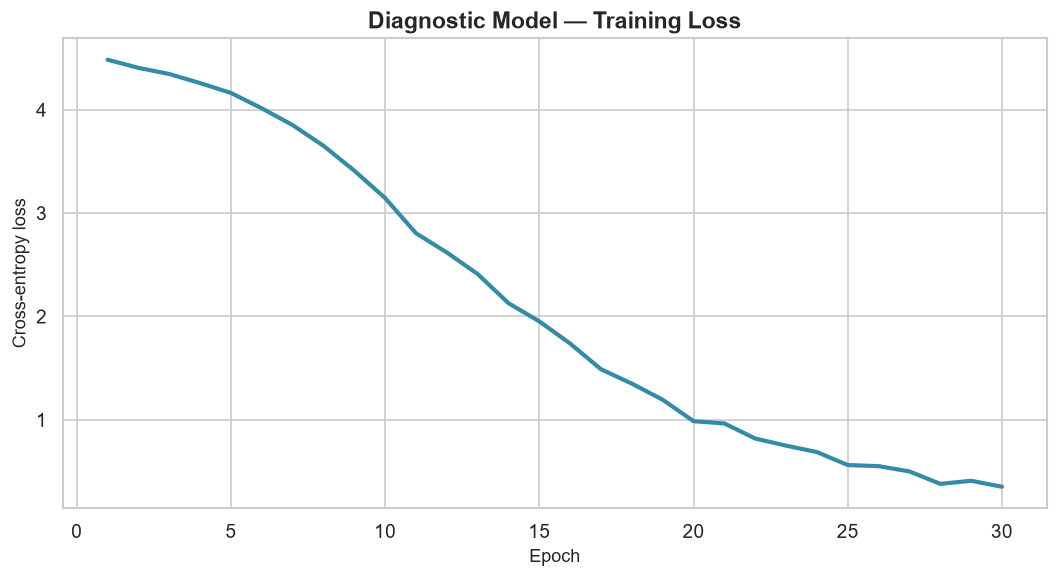

In [56]:
# 56 | Plot diagnostic training loss
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=diagnostic_history, x="epoch", y="loss", color=PALETTE[4], linewidth=2.5, ax=ax)
ax.set_title("Diagnostic Model — Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
fig.tight_layout()
save_figure(fig, "07_diagnostic_training_loss.png")
plt.show()

Saved image: 08_diagnostic_training_accuracy.png


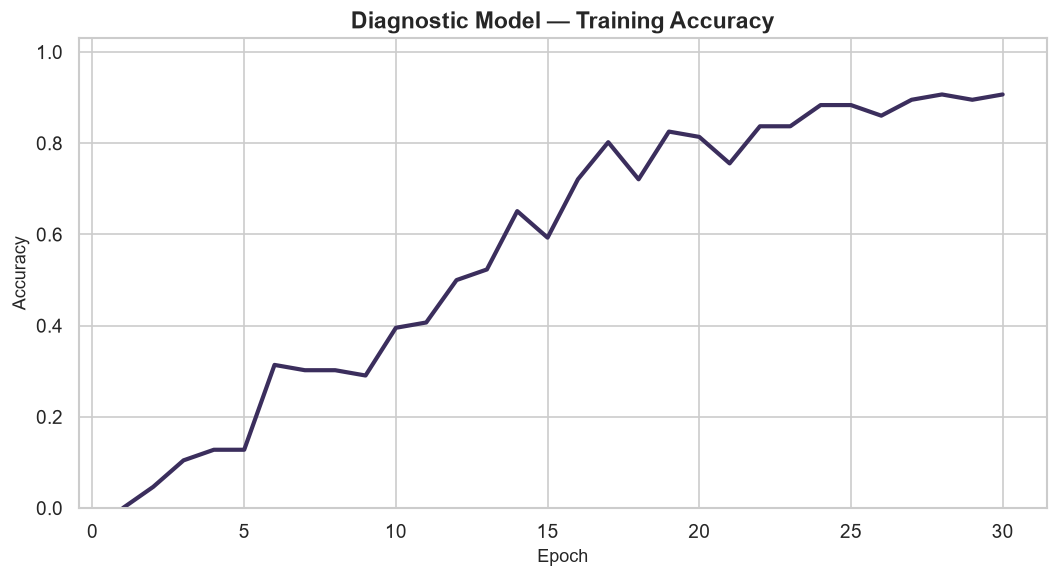

In [57]:
# 57 | Plot diagnostic training accuracy
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=diagnostic_history, x="epoch", y="accuracy", color=PALETTE[1], linewidth=2.5, ax=ax)
ax.set_title("Diagnostic Model — Training Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.03)
fig.tight_layout()
save_figure(fig, "08_diagnostic_training_accuracy.png")
plt.show()

In [58]:
# 58 | Define batch prediction for evaluation
def predict_loader(model, loader, device):
    model.eval()
    all_predictions, all_targets, all_probabilities = [], [], []
    with torch.no_grad():
        for token_ids, lengths, labels in loader:
            logits = model(token_ids.to(device), lengths)
            probabilities = torch.softmax(logits, dim=1).cpu().numpy()
            all_probabilities.append(probabilities)
            all_predictions.extend(logits.argmax(dim=1).cpu().tolist())
            all_targets.extend(labels.tolist())
    if all_probabilities:
        all_probabilities = np.vstack(all_probabilities)
    else:
        all_probabilities = np.empty((0, NUM_CLASSES))
    return np.array(all_predictions), np.array(all_targets), all_probabilities

print("Evaluation helper defined.")

Evaluation helper defined.


In [59]:
# 59 | Evaluate the diagnostic model
val_predictions, val_targets, val_probabilities = predict_loader(diagnostic_model, val_loader, DEVICE)
validation_accuracy = accuracy_score(val_targets, val_predictions) if len(val_targets) else float("nan")
validation_top3 = float("nan")
if len(val_targets):
    validation_top3 = np.mean([
        target in np.argsort(probabilities)[-3:]
        for target, probabilities in zip(val_targets, val_probabilities)
    ])

print(f"Validation accuracy: {validation_accuracy:.1%}")
print(f"Validation top-3 accuracy: {validation_top3:.1%}")

Validation accuracy: 0.0%
Validation top-3 accuracy: 25.0%


In [60]:
# 60 | Review validation predictions
validation_review = val_df[["question", "answer"]].copy()
validation_review["predicted_answer"] = [idx_to_answer[index] for index in val_predictions]
validation_review["correct"] = validation_review["answer"] == validation_review["predicted_answer"]
display(validation_review)

,question,answer,predicted_answer,correct
0,How many legs does a spider have?,8,6,False
1,How many colors are in a rainbow?,7,206,False
2,What is the first element on the periodic table?,Hydrogen,Whale,False
3,Which planet is the closest to the Sun?,Mercury,Cheetah,False


In [61]:
# 61 | Generate a compact diagnostic classification report
if len(val_targets):
    evaluated_classes = sorted(set(val_targets.tolist()))
    print(classification_report(
        val_targets,
        val_predictions,
        labels=evaluated_classes,
        target_names=[idx_to_answer[index] for index in evaluated_classes],
        zero_division=0,
    ))
else:
    print("No validation records are available for this dataset.")

              precision    recall  f1-score   support

           7       0.00      0.00      0.00       1.0
           8       0.00      0.00      0.00       1.0
    Hydrogen       0.00      0.00      0.00       1.0
     Mercury       0.00      0.00      0.00       1.0

   micro avg       0.00      0.00      0.00       4.0
   macro avg       0.00      0.00      0.00       4.0
weighted avg       0.00      0.00      0.00       4.0



Saved image: 09_validation_confusion_matrix.png


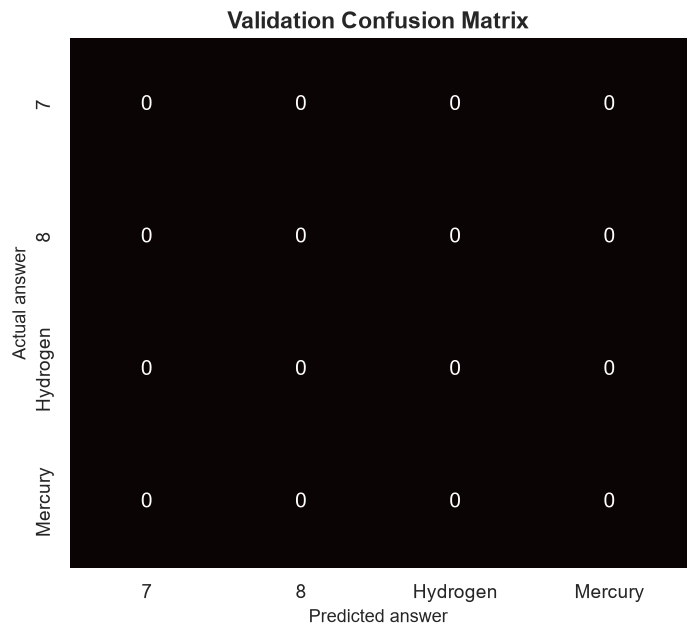

In [62]:
# 62 | Plot the small validation confusion matrix
if len(val_targets):
    evaluated_classes = sorted(set(val_targets.tolist()))
    matrix = confusion_matrix(val_targets, val_predictions, labels=evaluated_classes)
    labels_for_plot = [idx_to_answer[index] for index in evaluated_classes]
    fig, ax = plt.subplots(figsize=(max(6, len(labels_for_plot) * 1.2), 5.5))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="mako", xticklabels=labels_for_plot, yticklabels=labels_for_plot, cbar=False, ax=ax)
    ax.set_title("Validation Confusion Matrix")
    ax.set_xlabel("Predicted answer")
    ax.set_ylabel("Actual answer")
    fig.tight_layout()
    save_figure(fig, "09_validation_confusion_matrix.png")
    plt.show()
else:
    print("Confusion matrix skipped because validation is empty.")

In [63]:
# 63 | Inspect confidence on validation examples
if len(val_targets):
    validation_confidence = val_probabilities.max(axis=1)
    confidence_frame = pd.DataFrame({
        "question": val_df["question"].tolist(),
        "actual": [idx_to_answer[index] for index in val_targets],
        "predicted": [idx_to_answer[index] for index in val_predictions],
        "confidence": validation_confidence,
    })
    display(confidence_frame.round({"confidence": 3}))
else:
    confidence_frame = pd.DataFrame(columns=["question", "actual", "predicted", "confidence"])
    print("No validation confidence values to inspect.")

,question,actual,predicted,confidence
0,How many legs does a spider have?,8,6,0.837
1,How many colors are in a rainbow?,7,206,0.543
2,What is the first element on the periodic table?,Hydrogen,Whale,0.293
3,Which planet is the closest to the Sun?,Mercury,Cheetah,0.442


Saved image: 10_validation_confidence.png


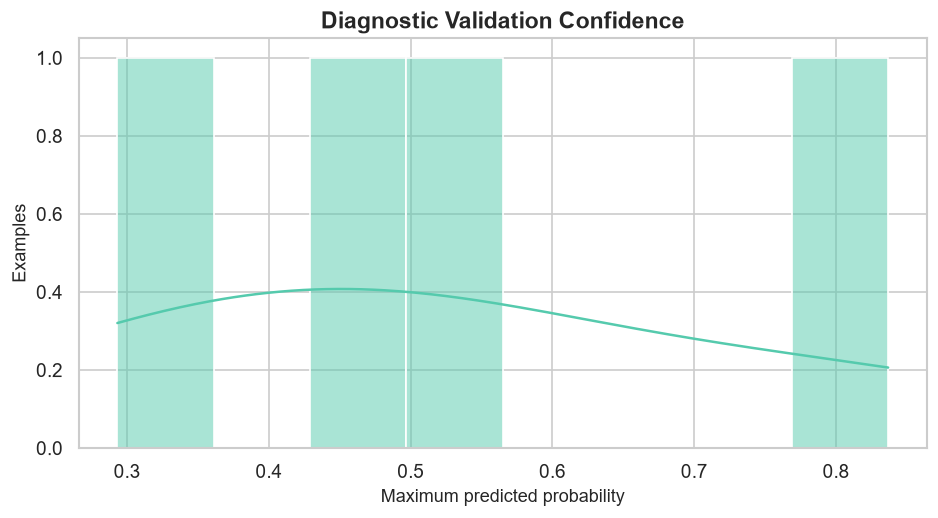

In [64]:
# 64 | Plot validation confidence values
if not confidence_frame.empty:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.histplot(confidence_frame["confidence"], bins=8, color=PALETTE[6], kde=True, ax=ax)
    ax.set_title("Diagnostic Validation Confidence")
    ax.set_xlabel("Maximum predicted probability")
    ax.set_ylabel("Examples")
    fig.tight_layout()
    save_figure(fig, "10_validation_confidence.png")
    plt.show()
else:
    print("Confidence chart skipped.")

In [65]:
# 65 | Explain the validation limitation
validation_note = (
    f"The diagnostic validation contains {len(val_df)} records drawn only from answer labels "
    "that appear more than once. Most answer labels occur once, so this is a narrow consistency "
    "check rather than a statistically strong estimate of real-world generalization."
)
display(Markdown(f"> **Evaluation note:** {validation_note}"))

> **Evaluation note:** The diagnostic validation contains 4 records drawn only from answer labels that appear more than once. Most answer labels occur once, so this is a narrow consistency check rather than a statistically strong estimate of real-world generalization.

## 3. Text preprocessing

Question tokens are lowercased, punctuation is removed, and compound names containing hyphens or apostrophes are preserved as one token. Padding and unknown-token IDs are reserved explicitly.

In [66]:
# 66 | Rebuild the vocabulary using all available questions for the final model
final_vocab = build_vocab(df["question"].tolist())
print(f"Final question vocabulary size: {len(final_vocab)}")

Final question vocabulary size: 246


In [67]:
# 67 | Build the final training dataset and loader
final_dataset = QAPairDataset(df, final_vocab, answer_to_idx)
final_generator = torch.Generator().manual_seed(SEED)
final_loader = DataLoader(
    final_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_qa_batch,
    generator=final_generator,
)

print(f"Final training records: {len(final_dataset)}")

Final training records: 90


In [68]:
# 68 | Initialize the final BiGRU model
final_model = BiGRUAnswerClassifier(
    vocab_size=len(final_vocab),
    num_classes=NUM_CLASSES,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout=DROPOUT_RATE,
).to(DEVICE)

print("Final model initialized.")

Final model initialized.


In [69]:
# 69 | Set final training controls
FINAL_EPOCHS = 50
FINAL_LEARNING_RATE = 0.0025
FINAL_WEIGHT_DECAY = 1e-4

print(f"Final training configured for {FINAL_EPOCHS} epochs.")

Final training configured for 50 epochs.


In [70]:
# 70 | Train the final model on all available examples
final_history = fit_model(
    final_model,
    final_loader,
    epochs=FINAL_EPOCHS,
    learning_rate=FINAL_LEARNING_RATE,
    weight_decay=FINAL_WEIGHT_DECAY,
    device=DEVICE,
)

print("Final model training completed.")

Epoch 001/50 | loss 4.4788 | accuracy 0.0%
Epoch 010/50 | loss 3.4485 | accuracy 17.8%
Epoch 020/50 | loss 1.4402 | accuracy 73.3%
Epoch 030/50 | loss 0.4722 | accuracy 90.0%
Epoch 040/50 | loss 0.1812 | accuracy 95.6%
Epoch 050/50 | loss 0.0606 | accuracy 98.9%
Final model training completed.


In [71]:
# 71 | Review final training metrics
display(final_history.tail(10).round(4))

,epoch,loss,accuracy
40,41,0.1130,1.0000
41,42,0.1697,0.9556
42,43,0.1096,1.0000
43,44,0.0818,1.0000
44,45,0.0836,0.9778
45,46,0.0765,1.0000
46,47,0.0612,1.0000
47,48,0.1374,0.9778
48,49,0.0744,0.9889
49,50,0.0606,0.9889


Saved image: 11_final_training_curves.png


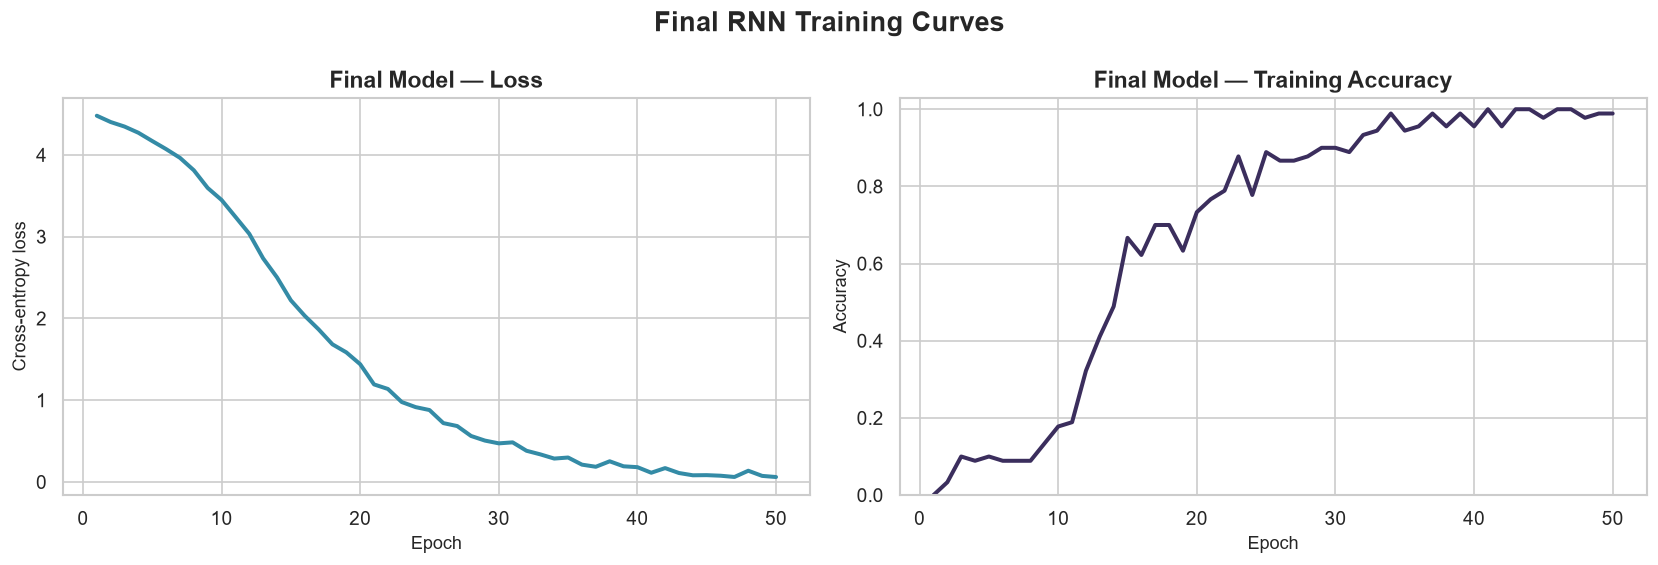

In [72]:
# 72 | Plot final model loss and accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.lineplot(data=final_history, x="epoch", y="loss", color=PALETTE[4], linewidth=2.4, ax=axes[0])
axes[0].set_title("Final Model — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
sns.lineplot(data=final_history, x="epoch", y="accuracy", color=PALETTE[1], linewidth=2.4, ax=axes[1])
axes[1].set_title("Final Model — Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.03)
fig.suptitle("Final RNN Training Curves", fontsize=16, fontweight="bold")
fig.tight_layout()
save_figure(fig, "11_final_training_curves.png")
plt.show()

In [73]:
# 73 | Calculate final training-set metrics
final_train_predictions, final_train_targets, final_train_probabilities = predict_loader(final_model, final_loader, DEVICE)
final_train_accuracy = accuracy_score(final_train_targets, final_train_predictions)
final_train_top3 = np.mean([
    target in np.argsort(probabilities)[-3:]
    for target, probabilities in zip(final_train_targets, final_train_probabilities)
])
print(f"In-sample accuracy: {final_train_accuracy:.1%}")
print(f"In-sample top-3 accuracy: {final_train_top3:.1%}")

In-sample accuracy: 100.0%
In-sample top-3 accuracy: 100.0%


In [74]:
# 74 | Review examples the final model has learned
final_review = df[["question", "answer"]].copy()
final_review["predicted_answer"] = [idx_to_answer[index] for index in final_train_predictions]
final_review["confidence"] = final_train_probabilities.max(axis=1)
final_review["correct"] = final_review["answer"] == final_review["predicted_answer"]
display(final_review.head(12).round({"confidence": 3}))

,question,answer,predicted_answer,confidence,correct
0,What is the capital of France?,Paris,Yen,0.996,False
1,What is the capital of Germany?,Berlin,Shakespeare,0.985,False
2,Who wrote 'To Kill a Mockingbird'?,Harper-Lee,MargaretThatcher,0.998,False
3,What is the largest planet in our solar system?,Jupiter,Piano,0.998,False
4,What is the boiling point of water in Celsius?,100,Biology,0.999,False
5,Who painted the Mona Lisa?,Leonardo-da-Vinci,"299,792,458m/s",0.972,False
6,What is the square root of 64?,8,Nitrogen,0.968,False
7,What is the chemical symbol for gold?,Au,Newton,0.999,False
8,Which year did World War II end?,1945,Whale,0.988,False
9,What is the longest river in the world?,Nile,Harper-Lee,0.998,False


Saved image: 12_final_model_confidence.png


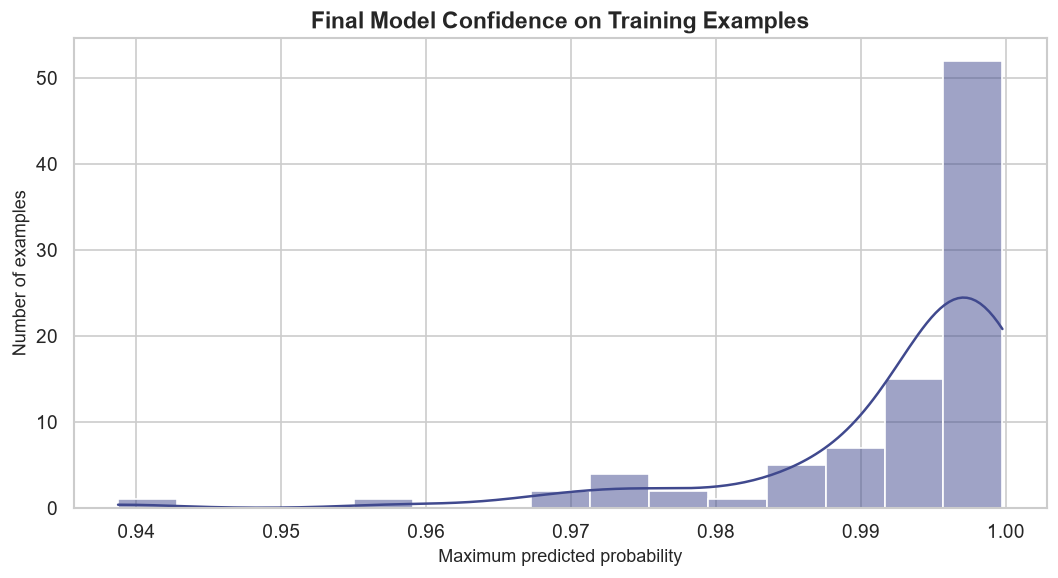

In [75]:
# 75 | Plot final model confidence distribution
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(final_review["confidence"], bins=15, kde=True, color=PALETTE[2], ax=ax)
ax.set_title("Final Model Confidence on Training Examples")
ax.set_xlabel("Maximum predicted probability")
ax.set_ylabel("Number of examples")
fig.tight_layout()
save_figure(fig, "12_final_model_confidence.png")
plt.show()

## 4. PyTorch data pipeline and model

The classifier uses an embedding layer, a bidirectional GRU encoder, masked mean/max pooling, and a multilayer classifier. Variable-length questions are padded per batch; sequence lengths are passed to the packed GRU so padding does not become part of the encoded question.

In [76]:
# 76 | Create the TF-IDF retrieval index
# Retrieval is included because a tiny FAQ dataset benefits from an exact/nearest-question path.
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    sublinear_tf=True,
    norm="l2",
)
tfidf_matrix = tfidf_vectorizer.fit_transform(df["question"].tolist())
print("TF-IDF retrieval index fitted.")

TF-IDF retrieval index fitted.


In [77]:
# 77 | Build an exact-question lookup table
exact_answer_lookup = {
    normalize_text(question): answer
    for question, answer in zip(df["question"], df["answer"])
}
print(f"Exact lookup entries: {len(exact_answer_lookup)}")

Exact lookup entries: 90


In [78]:
# 78 | Define nearest-question retrieval

def retrieve_nearest_question(question, top_k=3):
    query_vector = tfidf_vectorizer.transform([str(question)])
    similarities = (tfidf_matrix @ query_vector.T).toarray().ravel()
    ranked_indices = np.argsort(similarities)[::-1][:top_k]
    results = []
    for index in ranked_indices:
        results.append({
            "matched_question": df.iloc[int(index)]["question"],
            "answer": df.iloc[int(index)]["answer"],
            "similarity": float(similarities[index]),
        })
    return results

print("Nearest-question retrieval function defined.")

Nearest-question retrieval function defined.


In [79]:
# 79 | Define neural top-k prediction

def neural_top_predictions(question, top_k=3):
    final_model.eval()
    encoded = text_to_indices(question, final_vocab)
    token_tensor = torch.tensor(encoded, dtype=torch.long).unsqueeze(0).to(DEVICE)
    lengths = torch.tensor([len(encoded)], dtype=torch.long)
    with torch.no_grad():
        logits = final_model(token_tensor, lengths)
        probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    top_indices = np.argsort(probabilities)[::-1][:top_k]
    return [
        {"answer": idx_to_answer[int(index)], "confidence": float(probabilities[index])}
        for index in top_indices
    ]

print("Neural prediction function defined.")

Neural prediction function defined.


In [80]:
# 80 | Define a hybrid answer function with abstention

def answer_question(question, retrieval_threshold=0.32, neural_threshold=0.55, support_threshold=0.12):
    """Answer exact matches, retrieve close questions, use the GRU when supported, or abstain."""
    question = str(question).strip()
    if not question:
        return {"question": question, "answer": "Please enter a question.", "method": "input check", "confidence": 0.0, "similarity": 0.0, "matched_question": ""}

    normalized = normalize_text(question)
    if normalized in exact_answer_lookup:
        exact_answer = exact_answer_lookup[normalized]
        return {"question": question, "answer": exact_answer, "method": "exact match", "confidence": 1.0, "similarity": 1.0, "matched_question": question}

    nearest = retrieve_nearest_question(question, top_k=1)[0]
    neural_best = neural_top_predictions(question, top_k=1)[0]

    if nearest["similarity"] >= retrieval_threshold:
        return {"question": question, "answer": nearest["answer"], "method": "TF-IDF retrieval", "confidence": neural_best["confidence"], "similarity": nearest["similarity"], "matched_question": nearest["matched_question"]}

    if neural_best["confidence"] >= neural_threshold and nearest["similarity"] >= support_threshold:
        return {"question": question, "answer": neural_best["answer"], "method": "BiGRU classifier", "confidence": neural_best["confidence"], "similarity": nearest["similarity"], "matched_question": nearest["matched_question"]}

    return {"question": question, "answer": "I don't know.", "method": "abstained", "confidence": neural_best["confidence"], "similarity": nearest["similarity"], "matched_question": nearest["matched_question"]}

print("Hybrid QA pipeline is ready.")

Hybrid QA pipeline is ready.


In [81]:
# 81 | Ask a known question
example_result = answer_question("What is the capital of France?")
display(pd.Series(example_result, name="result").to_frame())

,result
question,What is the capital of France?
answer,Paris
method,exact match
confidence,1.0
similarity,1.0
matched_question,What is the capital of France?


In [82]:
# 82 | Ask a lightly rephrased question
paraphrase_result = answer_question("What is the capital city of France?")
display(pd.Series(paraphrase_result, name="result").to_frame())

,result
question,What is the capital city of France?
answer,Paris
method,TF-IDF retrieval
confidence,0.991663
similarity,0.839205
matched_question,What is the capital of France?


In [83]:
# 83 | Ask a question outside the supplied knowledge base
unknown_result = answer_question("Who won the 2022 FIFA World Cup?")
display(pd.Series(unknown_result, name="result").to_frame())

,result
question,Who won the 2022 FIFA World Cup?
answer,I don't know.
method,abstained
confidence,0.42942
similarity,0.290194
matched_question,What is the smallest country in the world?


In [84]:
# 84 | Inspect the nearest FAQ matches for a new query
query_for_inspection = "Which city is the capital of Germany?"
retrieval_candidates = pd.DataFrame(retrieve_nearest_question(query_for_inspection, top_k=5))
display(retrieval_candidates.round({"similarity": 3}))

,matched_question,answer,similarity
0,What is the capital of Germany?,Berlin,0.699
1,Which city is known as the Big Apple?,NewYork,0.404
2,What is the capital of Japan?,Tokyo,0.325
3,What is the capital of Brazil?,Brasilia,0.317
4,What is the capital of Spain?,Madrid,0.311


In [85]:
# 85 | Inspect top neural predictions for a question
neural_candidates = pd.DataFrame(neural_top_predictions("Which planet is known as the Red Planet?", top_k=5))
display(neural_candidates.round({"confidence": 3}))

,answer,confidence
0,Mars,0.990
1,Mango,0.005
2,Batman,0.003
3,Mercury,0.002
4,France,0.000


In [86]:
# 86 | Compare the three answer routes on sample questions
sample_queries = [
    "What is the capital of France?",
    "What is the capital city of Germany?",
    "What is the chemical symbol for gold?",
    "Who won the 2022 FIFA World Cup?",
]
sample_results = pd.DataFrame([answer_question(query) for query in sample_queries])
display(sample_results[["question", "answer", "method", "confidence", "similarity"]].round({"confidence": 3, "similarity": 3}))

,question,answer,method,confidence,similarity
0,What is the capital of France?,Paris,exact match,1.000,1.000
1,What is the capital city of Germany?,Berlin,TF-IDF retrieval,0.993,0.839
2,What is the chemical symbol for gold?,Au,exact match,1.000,1.000
3,Who won the 2022 FIFA World Cup?,I don't know.,abstained,0.429,0.290


Saved image: 13_hybrid_route_distribution.png


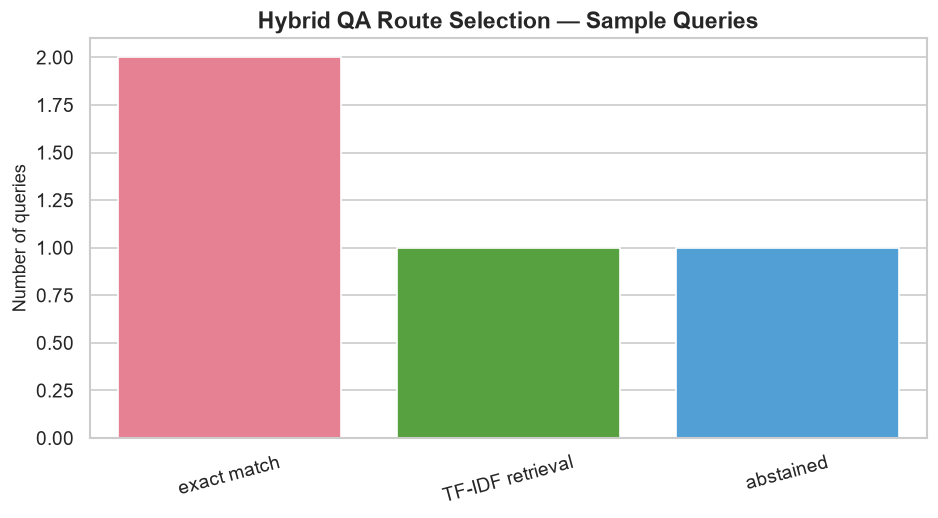

In [87]:
# 87 | Visualize the answer route distribution
route_counts = sample_results["method"].value_counts().rename_axis("method").reset_index(name="count")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=route_counts, x="method", y="count", hue="method", palette="husl", legend=False, ax=ax)
ax.set_title("Hybrid QA Route Selection — Sample Queries")
ax.set_xlabel("")
ax.set_ylabel("Number of queries")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
save_figure(fig, "13_hybrid_route_distribution.png")
plt.show()

Saved image: 14_known_question_similarity.png


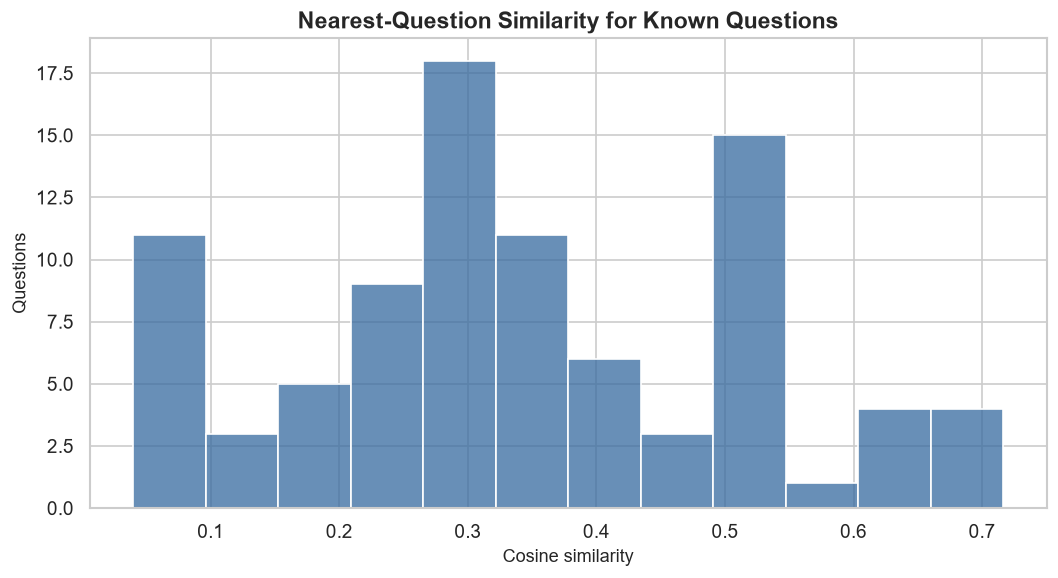

In [88]:
# 88 | Explore retrieval similarity for all known questions
known_similarity = []
for question in df["question"].tolist():
    candidates = retrieve_nearest_question(question, top_k=2)
    nearest_other = next(
        (item for item in candidates if normalize_text(item["matched_question"]) != normalize_text(question)),
        candidates[-1],
    )
    known_similarity.append(nearest_other["similarity"])

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(known_similarity, bins=12, kde=False, color=PALETTE[3], ax=ax)
ax.set_title("Nearest-Question Similarity for Known Questions")
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Questions")
fig.tight_layout()
save_figure(fig, "14_known_question_similarity.png")
plt.show()

In [89]:
# 89 | Validate common inference edge cases
edge_case_queries = ["", "   ", "What is the capital of France?", "Completely unrelated question about quantum cooking"]
edge_case_results = pd.DataFrame([answer_question(query) for query in edge_case_queries])
display(edge_case_results[["question", "answer", "method"]])

,question,answer,method
0,,Please enter a question.,input check
1,,Please enter a question.,input check
2,What is the capital of France?,Paris,exact match
3,Completely unrelated question about quantum cooking,I don't know.,abstained


In [90]:
# 90 | Create a simple interactive question function
def ask(question):
    result = answer_question(question)
    print(f"Question: {result['question']}")
    print(f"Answer:   {result['answer']}")
    print(f"Route:    {result['method']}")
    print(f"Confidence: {result['confidence']:.1%} | Similarity: {result['similarity']:.3f}")
    if result["matched_question"] and result["method"] not in {"exact match", "input check"}:
        print(f"Closest known question: {result['matched_question']}")
    return result

print("Use ask('your question here') to query the system.")

Use ask('your question here') to query the system.


## 5. Diagnostic evaluation

Most answer labels occur once. A conventional random holdout would place many answer classes only in validation, making them impossible for a supervised classifier to learn from training. Instead, one example from each repeated answer label is held out. This creates a very small validation set, so its metrics are diagnostic only and must not be presented as a robust estimate of generalization.

In [91]:
# 91 | Save the trained model checkpoint
checkpoint = {
    "model_state_dict": final_model.state_dict(),
    "vocabulary": final_vocab,
    "answer_to_index": answer_to_idx,
    "index_to_answer": idx_to_answer,
    "model_config": model_config,
    "seed": SEED,
    "token_pattern": TOKEN_PATTERN.pattern,
}
torch.save(checkpoint, ARTIFACT_DIR / "pytorch_rnn_qa_model.pt")
print("Model checkpoint saved successfully.")

Model checkpoint saved successfully.


In [92]:
# 92 | Save dataset and training metadata
metadata = {
    "dataset_name": DATASET_NAME,
    "num_records": int(len(df)),
    "num_unique_answers": int(NUM_CLASSES),
    "vocabulary_size": int(len(final_vocab)),
    "model_type": "Bidirectional GRU answer classifier",
    "answer_format": "single-token classification labels",
    "training_epochs": int(FINAL_EPOCHS),
    "embedding_dim": int(EMBEDDING_DIM),
    "hidden_dim": int(HIDDEN_DIM),
    "device_type": DEVICE.type,
    "seed": int(SEED),
}
with open(ARTIFACT_DIR / "model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)
print("Model metadata saved successfully.")

Model metadata saved successfully.


In [93]:
# 93 | Export the final vocabulary and answer labels
with open(ARTIFACT_DIR / "vocabulary.json", "w", encoding="utf-8") as file:
    json.dump(final_vocab, file, indent=2, ensure_ascii=False)
with open(ARTIFACT_DIR / "answer_labels.json", "w", encoding="utf-8") as file:
    json.dump({str(index): answer for index, answer in idx_to_answer.items()}, file, indent=2, ensure_ascii=False)
print("Vocabulary and answer labels exported.")

Vocabulary and answer labels exported.


In [94]:
# 94 | Save training and validation metrics
metrics = {
    "diagnostic_validation_accuracy": float(validation_accuracy) if not math.isnan(validation_accuracy) else None,
    "diagnostic_validation_top3_accuracy": float(validation_top3) if not math.isnan(validation_top3) else None,
    "final_in_sample_accuracy": float(final_train_accuracy),
    "final_in_sample_top3_accuracy": float(final_train_top3),
    "validation_records": int(len(val_df)),
    "validation_warning": "Small repeated-label-only validation set; not a robust generalization estimate.",
}
with open(ARTIFACT_DIR / "evaluation_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
print("Evaluation metrics exported.")

Evaluation metrics exported.


In [95]:
# 95 | Export training histories
final_history.to_csv(ARTIFACT_DIR / "final_training_history.csv", index=False)
diagnostic_history.to_csv(ARTIFACT_DIR / "diagnostic_training_history.csv", index=False)
print("Training histories exported.")

Training histories exported.


In [96]:
# 96 | Export the sample prediction log
prediction_log = sample_results.copy()
prediction_log.to_csv(ARTIFACT_DIR / "sample_prediction_log.csv", index=False)
print("Sample prediction log exported.")

Sample prediction log exported.


In [97]:
# 97 | Persist the TF-IDF retrieval index
joblib.dump(tfidf_vectorizer, ARTIFACT_DIR / "tfidf_vectorizer.joblib")
print("Retrieval vectorizer exported.")

Retrieval vectorizer exported.


Saved image: 15_embedding_pca.png


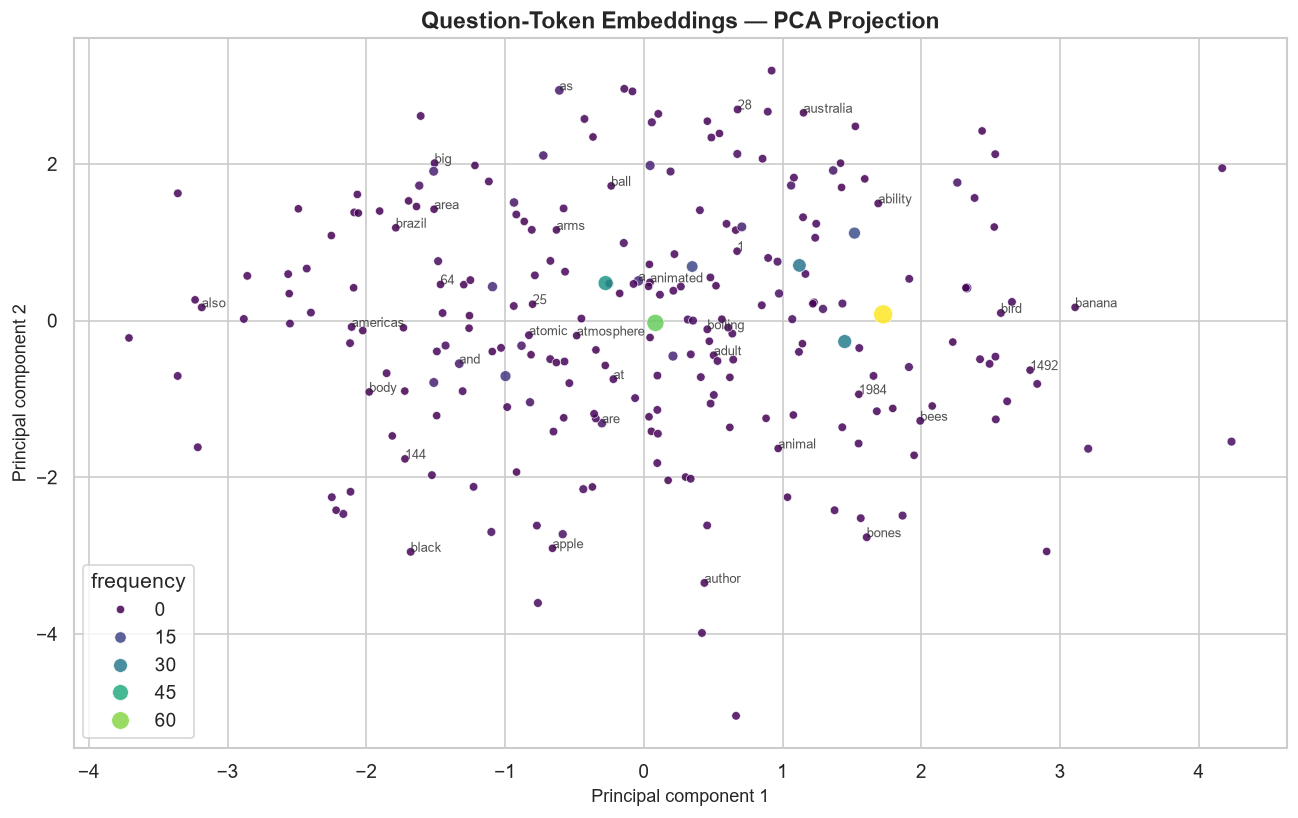

In [98]:
# 98 | Visualize learned word embeddings with PCA
embedding_weights = final_model.embedding.weight.detach().cpu().numpy()
selected_tokens = [token for token in final_vocab if token not in {PAD_TOKEN, UNK_TOKEN}]
selected_ids = [final_vocab[token] for token in selected_tokens]
if len(selected_ids) >= 3:
    pca = PCA(n_components=2, random_state=SEED)
    embedding_2d = pca.fit_transform(embedding_weights[selected_ids])
    embedding_plot = pd.DataFrame({"token": selected_tokens, "pc1": embedding_2d[:, 0], "pc2": embedding_2d[:, 1]})
    embedding_plot["frequency"] = embedding_plot["token"].map(question_word_counts).fillna(1)
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.scatterplot(data=embedding_plot, x="pc1", y="pc2", hue="frequency", palette="viridis", size="frequency", sizes=(25, 130), alpha=0.85, ax=ax)
    for _, row in embedding_plot.head(35).iterrows():
        ax.annotate(row["token"], (row["pc1"], row["pc2"]), fontsize=8, alpha=0.8)
    ax.set_title("Question-Token Embeddings — PCA Projection")
    ax.set_xlabel("Principal component 1")
    ax.set_ylabel("Principal component 2")
    fig.tight_layout()
    save_figure(fig, "15_embedding_pca.png")
    plt.show()
else:
    print("Not enough tokens for a two-dimensional embedding plot.")

In [99]:
# 99 | Summarize generated deliverables
artifact_summary = pd.DataFrame({
    "deliverable": [
        "Trained PyTorch model", "Model metadata", "Question vocabulary", "Answer labels",
        "Evaluation metrics", "Training histories", "Prediction log", "TF-IDF vectorizer"
    ],
    "saved": [True] * 8,
})
display(artifact_summary)
print(f"Saved {len(list(IMAGE_DIR.glob('*.png')))} image files and {len(list(ARTIFACT_DIR.iterdir()))} artifact files.")

,deliverable,saved
0,Trained PyTorch model,True
1,Model metadata,True
2,Question vocabulary,True
3,Answer labels,True
4,Evaluation metrics,True
5,Training histories,True
6,Prediction log,True
7,TF-IDF vectorizer,True


Saved 135 image files and 93 artifact files.


In [100]:
# 100 | Final integrity checks and completion summary
assert (ARTIFACT_DIR / "pytorch_rnn_qa_model.pt").is_file()
assert (ARTIFACT_DIR / "model_metadata.json").is_file()
assert len(list(IMAGE_DIR.glob("*.png"))) >= 8
assert len(final_vocab) >= 2

print("Notebook workflow completed successfully.")
print(f"Records processed: {len(df)} | Answer classes: {NUM_CLASSES} | Vocabulary terms: {len(final_vocab)}")
print("Outputs are organized in images/ and artifacts/.")

Notebook workflow completed successfully.
Records processed: 90 | Answer classes: 85 | Vocabulary terms: 246
Outputs are organized in images/ and artifacts/.


## 6. Final training

After the diagnostic run, a fresh vocabulary and model are trained on all available question–answer pairs. The resulting in-sample scores measure how well the model learned the supplied examples; they are not an independent test score.

## 7. Hybrid question answering

The inference pipeline prioritizes exact question matches, then TF-IDF nearest-question retrieval, then a confidence-gated GRU classification. When similarity and confidence are both weak, the system abstains with “I don't know.” The thresholds are conservative starting points and should be calibrated on a larger, representative evaluation set.

## 8. Artifacts and reproducibility

The final cells export the PyTorch checkpoint, model metadata, vocabularies, label mappings, evaluation metrics, training histories, sample predictions, and the TF-IDF vectorizer. The saved model can be reused by loading its checkpoint and reconstructing the same `BiGRUAnswerClassifier` architecture.

## Interpretation and limitations

- **Small data:** 90 examples are insufficient for broad language understanding or reliable generalization.
- **Single-token labels:** the current dataset supports classification because every answer is a single token. Multi-word answers require a sequence-to-sequence generation model or a different formulation.
- **Closed answer space:** the classifier can only select one of the answer labels observed in the dataset.
- **Retrieval scope:** TF-IDF finds lexical similarity, not deep semantic equivalence.
- **Confidence is not certainty:** softmax probabilities are not calibrated probabilities of correctness.
- **Recommended next step:** collect substantially more examples, add realistic paraphrases and out-of-domain questions, and create a separate test set with repeated answer classes.